# Statistical Methods in AI – Monsoon 2026
## Assignment 1: Automated Essay Scoring & Bayesian Machine Learning
**Instructors:** Prof. Anoop M. Namboodiri, Prof. Saikiran Bulusu  
**Student Name:** Devansh Bansal  
**Username / Email Prefix:** `devansh.bansal`  
**Institute Email:** `devansh.bansal@research.iiit.ac.in`  


## 0. Global Setup, Reproducibility, & Watermarking

As specified in the assignment instructions, we generate a unique, reproducible random seed by computing the SHA-256 hash of the institute email ID prefix (`devansh.bansal`):
$$\text{seed} = \text{int}\Big(\text{SHA-256}(\text{username})\Big)_{16} \pmod{2^{32}}$$

This seed is used consistently across all random sampling routines and data partitioning.

In [107]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import enum
import heapq
from PIL import Image
from IPython.display import display
import scipy.special as sp

USERNAME = "devansh.bansal"
SEED = int(hashlib.sha256(USERNAME.encode()).hexdigest(), 16) % (2**32)
print(f"Institute Username : {USERNAME}")
print(f"Computed Random Seed: {SEED}")

Institute Username : devansh.bansal
Computed Random Seed: 2023333423


# 1. Automated Essay Scoring System

Automated Essay Scoring (AES) is a fundamental application of statistical learning in educational measurement and large-scale standardized testing. The objective is to automatically evaluate the quality of an essay and assign a score $y \in \{1, 2, 3, 4, 5, 6\}$ based on handcrafted statistical and structural features computed directly from the raw text, without using heavy pre-trained language models or black-box NLP packages.

In [108]:

df_essays = pd.read_csv("essay_dataset.csv")
print(f"Dataset Shape: {df_essays.shape}")
print(f"Columns: {list(df_essays.columns)}")
display(df_essays.head(5)) 
# print to check columns and if the data is correct

Dataset Shape: (17307, 3)
Columns: ['essay_id', 'essay', 'score']


,essay_id,essay,score
0,000d118,Many people have car where they live. The thin...,3
1,000fe60,I am a scientist at NASA that is discussing th...,3
2,001ab80,People always wish they had the same technolog...,4
3,001bdc0,"We all heard about Venus, the planet without a...",4
4,002ba53,"Dear, State SenatorThis is a letter to argue i...",3


## 1.1 Feature Engineering [15 marks]

### Linguistic Motivation & Feature Design
To capture the multidimensional attributes of essay quality without external NLP libraries, we engineer **15 handcrafted statistical features** spanning lexical richness, syntactic complexity, text length, and structural organization:

1. **Length & Volume Features**:
   - `total_words`: Total token count. Higher-scoring essays consistently demonstrate deeper topical exploration and argument development.
   - `total_sentences`: Total sentence count. Measures textual depth and narrative volume.
   - `num_paragraphs`: Number of structural paragraphs. Strong essays exhibit coherent paragraph organisation.

2. **Word-Length Distribution & Vocabulary Sophistication**:
   - `num_short_words`: Count of words with $\le 3$ characters (function words, prepositions, basic nouns).
   - `num_medium_words`: Count of words with $4 - 7$ characters (standard vocabulary).
   - `num_long_words`: Count of words with $\ge 8$ characters. Long words strongly correlate with advanced, domain-specific, and scholarly terminology.
   - `avg_word_length`: Mean character length per word $\frac{1}{N}\sum |w_i|$. Direct indicator of lexical sophistication.

3. **Syntactic Complexity & Sentence Structure**:
   - `num_short_sentences`: Sentences with $< 10$ words.
   - `num_medium_sentences`: Sentences with $10 - 20$ words.
   - `num_long_sentences`: Sentences with $> 20$ words. Reflects compound-complex syntactic maturity.
   - `avg_sentence_length`: Mean word count per sentence.
   - `sentence_len_std`: Standard deviation of sentence length. High variance indicates dynamic syntactic variation and engaging rhetorical style.

4. **Lexical Diversity & Punctuation**:
   - `lexical_diversity` (Type-Token Ratio, TTR): $\frac{|\text{Unique Words}|}{|\text{Total Words}|}$. Measures vocabulary range and resistance to repetitive phrasing.
   - `punctuation_count`: Total punctuation marks (commas, semicolons, dashes, etc.).
   - `punctuation_density`: Ratio of punctuation marks to total words, capturing syntactic punctuation nuance.

In [109]:
import re

class EssayFeatureExtractor:
    def __init__(self):
        pass

    def extract_features(self, essay: str) -> dict:
        '''tokenize an₫ find count and ratios to act as features for the given essay'''
        text = str(essay).strip()
        
        # Paragraph extraction
        paragraphs = [p.strip() for p in text.split('\n') if len(p.strip()) > 0]
        num_paragraphs = max(len(paragraphs), 1)
        
        # Sentence tokenization via punctuation splitting (. ! ?)
        raw_sentences = [s.strip() for s in re.split(r'[.!?]+', text) if len(s.strip()) > 0]
        if not raw_sentences:
            raw_sentences = [text]
        total_sentences = len(raw_sentences)
        
        # Word tokenization
        words = re.findall(r"\b[A-Za-z0-9'-]+\b", text)
        total_words = len(words)
        
        if total_words == 0:
            return {
                'total_words': 0, 'total_sentences': 0, 'num_short_words': 0,
                'num_medium_words': 0, 'num_long_words': 0, 'num_short_sentences': 0,
                'num_medium_sentences': 0, 'num_long_sentences': 0, 'avg_word_length': 0.0,
                'avg_sentence_length': 0.0, 'unique_words_ratio': 0.0, 'punctuation_count': 0,
                'punctuation_density': 0.0, 'num_paragraphs': 1, 'sentence_len_std': 0.0
            }
            
        word_lengths = [len(w) for w in words]
        num_short_words = sum(1 for l in word_lengths if l <= 3)
        num_medium_words = sum(1 for l in word_lengths if 4 <= l <= 7)
        num_long_words = sum(1 for l in word_lengths if l >= 8)
        
        # Sentence word lengths
        sentence_word_counts = []
        for s in raw_sentences:
            s_words = re.findall(r"\b[A-Za-z0-9'-]+\b", s)
            sentence_word_counts.append(len(s_words))
            
        num_short_sentences = sum(1 for c in sentence_word_counts if c < 10)
        num_medium_sentences = sum(1 for c in sentence_word_counts if 10 <= c <= 20)
        num_long_sentences = sum(1 for c in sentence_word_counts if c > 20)
        
        avg_word_length = float(np.mean(word_lengths))
        avg_sentence_length = float(np.mean(sentence_word_counts)) if sentence_word_counts else 0.0
        sentence_len_std = float(np.std(sentence_word_counts)) if sentence_word_counts else 0.0
        
        # Lexical diversity (Type-Token Ratio on lowercased words)
        unique_words = set(w.lower() for w in words)
        unique_words_ratio = float(len(unique_words) / total_words)
        
        # Punctuation counts
        punct_chars = {',', '.', ';', ':', '!', '?', "'", '"', '(', ')', '-'}
        punctuation_count = sum(1 for ch in text if ch in punct_chars)
        punctuation_density = float(punctuation_count / total_words)
        
        return {
            'total_words': total_words,
            'total_sentences': total_sentences,
            'num_short_words': num_short_words,
            'num_medium_words': num_medium_words,
            'num_long_words': num_long_words,
            'num_short_sentences': num_short_sentences,
            'num_medium_sentences': num_medium_sentences,
            'num_long_sentences': num_long_sentences,
            'avg_word_length': avg_word_length,
            'avg_sentence_length': avg_sentence_length,
            'unique_words_ratio': unique_words_ratio,
            'punctuation_count': punctuation_count,
            'punctuation_density': punctuation_density,
            'num_paragraphs': num_paragraphs,
            'sentence_len_std': sentence_len_std
        }

    def extract_dataset_features(self, essays) -> pd.DataFrame:
        '''extraction loop on all essay entries'''
        records = [self.extract_features(e) for e in essays]
        return pd.DataFrame(records)

# Instantiate and extract features
extractor = EssayFeatureExtractor()
df_features = extractor.extract_dataset_features(df_essays["essay"])
df_features["score"] = df_essays["score"].values

print("Feature extraction complete. First 5 feature vectors:")
display(df_features.head(5))

Feature extraction complete. First 5 feature vectors:


,total_words,total_sentences,num_short_words,num_medium_words,num_long_words,num_short_sentences,num_medium_sentences,num_long_sentences,avg_word_length,avg_sentence_length,unique_words_ratio,punctuation_count,punctuation_density,num_paragraphs,sentence_len_std,score
0,510,13,223,247,40,2,2,9,4.196078,39.230769,0.458824,40,0.078431,1,32.065207,3
1,332,21,153,152,27,5,10,6,3.903614,15.809524,0.439759,41,0.123494,1,10.219585,3
2,550,24,232,253,65,1,10,13,4.480000,22.916667,0.412727,56,0.101818,1,8.655040,4
3,452,21,176,197,79,1,11,9,4.842920,21.523810,0.484513,61,0.134956,1,8.813513,4
4,375,16,165,149,61,1,7,8,4.709333,23.437500,0.376000,41,0.109333,1,16.564151,3


## 1.2 Dataset Preprocessing [10 marks]

### 1.2.1 (a) Train-Validation-Test Split (80:10:10) [3 marks]
We split the dataset into Training (80%), Validation (10%), and Test (10%) sets deterministically using our institute random seed.

In [110]:
def train_val_test_split(df, train_ratio = 0.8, validation = 0.1, test_ratio = 0.1, seed=SEED):
    '''split the feature dataframe into train validate and test dataframes based of the ratios'''

    # to check completion
    if(train_ratio + validation + test_ratio == 1.0):
        print("yes")
    else:
        print("error")

    n = len(df)
    randomiser = np.random.default_rng(seed)
    indices = randomiser.permutation(n)

    train_n  = int(n*train_ratio)
    validate_n = int(n * validation)

    tr_indexes = indices[:train_n]
    va_indexes = indices[train_n : train_n + validate_n]
    te_indexes = indices[train_n + validate_n:]

    # .copy() because pandas sometimes link df and other dfs
    train_df = df.iloc[tr_indexes].copy()
    validation_df  = df.iloc[va_indexes].copy()
    test_df = df.iloc[te_indexes].copy()


    return train_df, validation_df, test_df

train_df, validation_df, test_df = train_val_test_split(df_features, 0.8, 0.1, 0.1, SEED)

print(f"Total Samples      : {len(df_features)}")
print(f"Training Samples   : {len(train_df)} ({len(train_df)/len(df_features):.1%})")
print(f"Validation Samples : {len(validation_df)} ({len(validation_df)/len(df_features):.1%})")
print(f"Test Samples       : {len(test_df)} ({len(test_df)/len(df_features):.1%})")

yes
Total Samples      : 17307
Training Samples   : 13845 (80.0%)
Validation Samples : 1730 (10.0%)
Test Samples       : 1732 (10.0%)


### 1.2.2 (b) Feature Normalization (Z-Score Standardization) [3 marks]

Because distance-based algorithms such as K-Nearest Neighbors compute metric distances in the feature space, features with large absolute scales (e.g., `total_words` $\approx 500$) would disproportionately dominate features with small numerical ranges (e.g., `lexical_diversity` $\in [0, 1]$).

We implement **Z-score standardization**:
$$z = \frac{x - \mu}{\sigma}$$

where $\mu$ and $\sigma$ are the empirical mean and standard deviation estimated **strictly from the training set**. These learned parameters are then applied without modification to standardize the validation and test feature vectors, preventing data leakage.

In [111]:
class zscorenormalizer:
    '''store and also normalizes based on mean and standard deviation'''
    def __init__(self):
        self.mean = None
        self.std = None
    
    def fit(self, X):
        '''take values from dataframe x as array and calculate mean and std'''

        self.mean = X.mean()
        self.std = X.std(ddof=0)

        self.std = self.std.replace(0,1)

        return self
    
    def transform(self, X):
        '''calculate the z score and return that normalized z score for each'''
        znorm  = (X-self.mean)/(self.std)
        return znorm

    def fit_transform(self,X):
        self.fit(X)
        return self.transform(X)


features = [c for c in train_df.columns if c != "score"]

scaler = zscorenormalizer()

x_train = scaler.fit_transform(train_df[features])
x_val = scaler.transform(validation_df[features])
x_test = scaler.transform(test_df[features])

y_train = train_df["score"].values
y_val = validation_df["score"].values
y_test = test_df["score"].values

print("Feature standardization complete.")
print(f"Training Mean Vector : \n{scaler.mean[:].round(3)}")
print(f"Training Std Vector  : \n{scaler.std[:].round(3)}")

Feature standardization complete.
Training Mean Vector : 
total_words             368.167
total_sentences          19.857
num_short_words         151.067
num_medium_words        174.705
num_long_words           42.394
num_short_sentences       3.232
num_medium_sentences      9.855
num_long_sentences        6.771
avg_word_length           4.430
avg_sentence_length      20.362
unique_words_ratio        0.480
punctuation_count        42.734
punctuation_density       0.114
num_paragraphs            1.000
sentence_len_std          9.205
dtype: float64
Training Std Vector  : 
total_words             149.645
total_sentences           8.819
num_short_words          62.241
num_medium_words         70.894
num_long_words           25.153
num_short_sentences       3.682
num_medium_sentences      5.724
num_long_sentences        4.103
avg_word_length           0.295
avg_sentence_length      13.911
unique_words_ratio        0.076
punctuation_count        24.455
punctuation_density       0.039
num_par

### 1.2.3 (c) Feature Visualizations [4 marks]

We provide 5 comprehensive visualizations examining feature distributions, target correlations, and score separability across the engineered feature space.

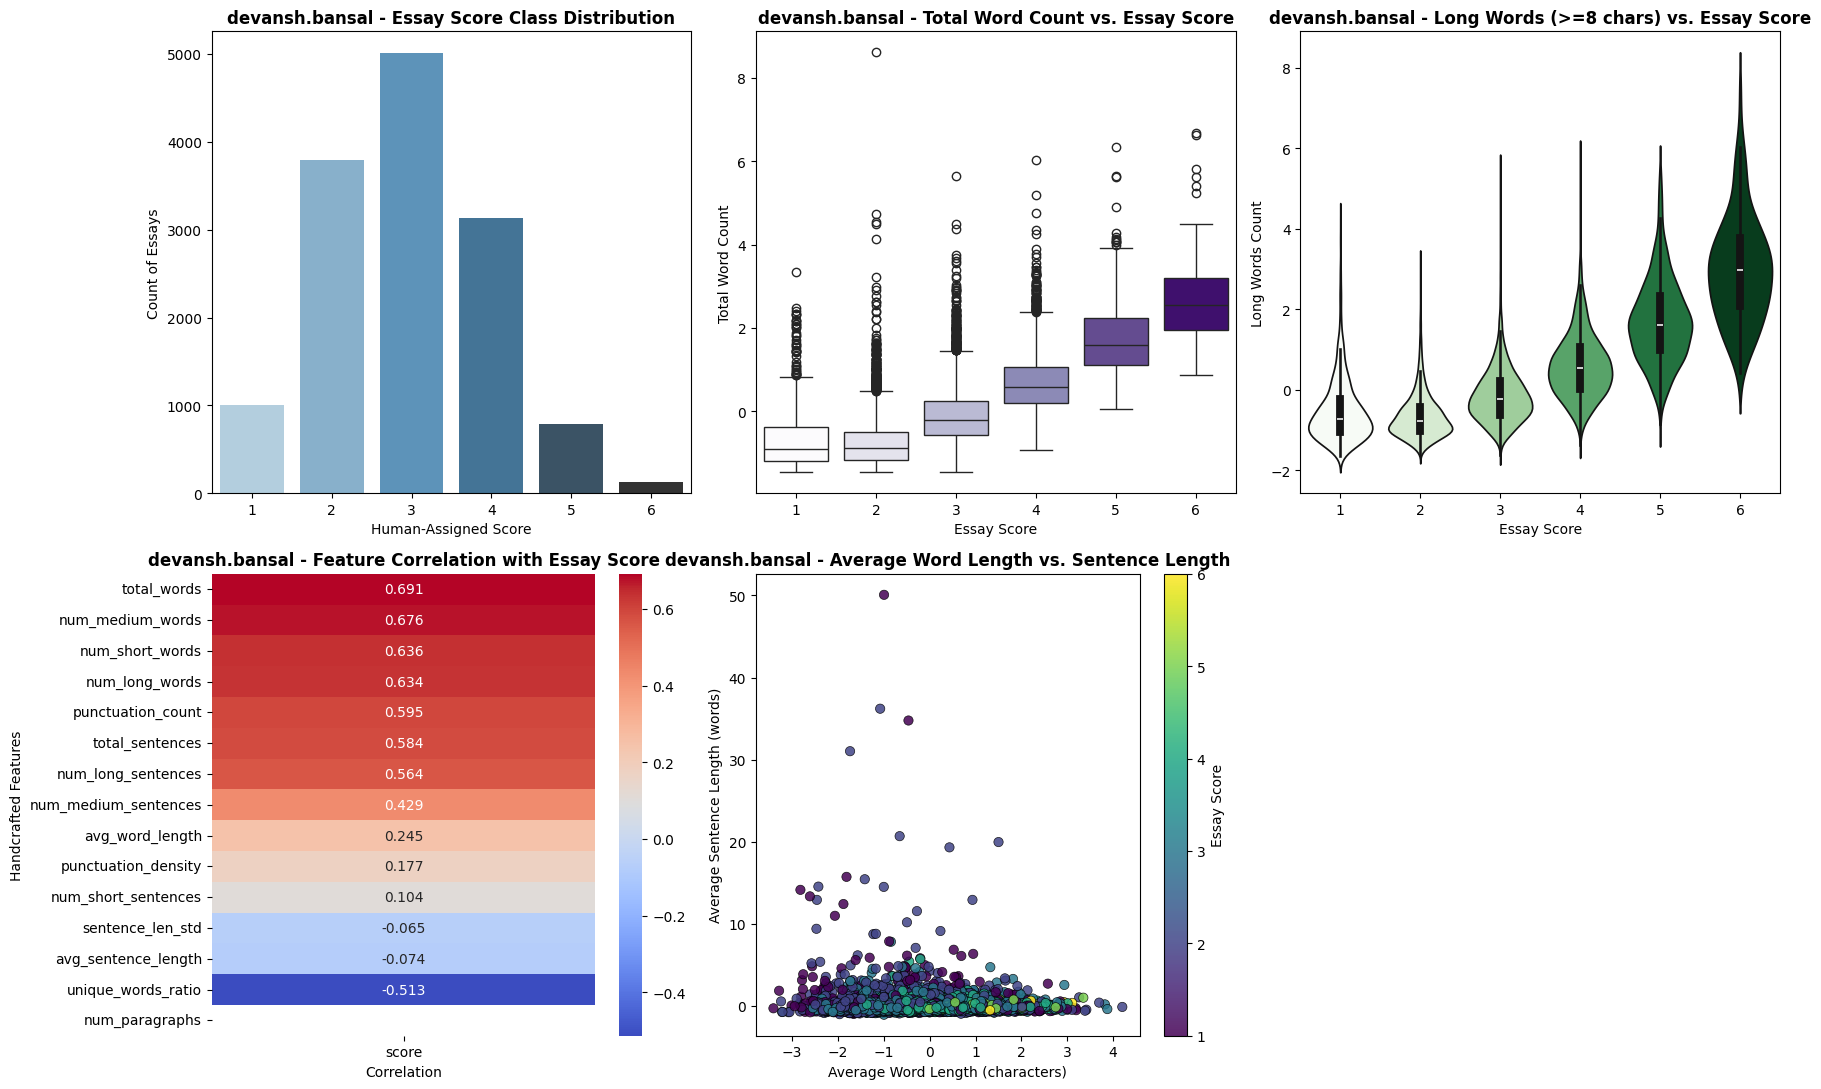

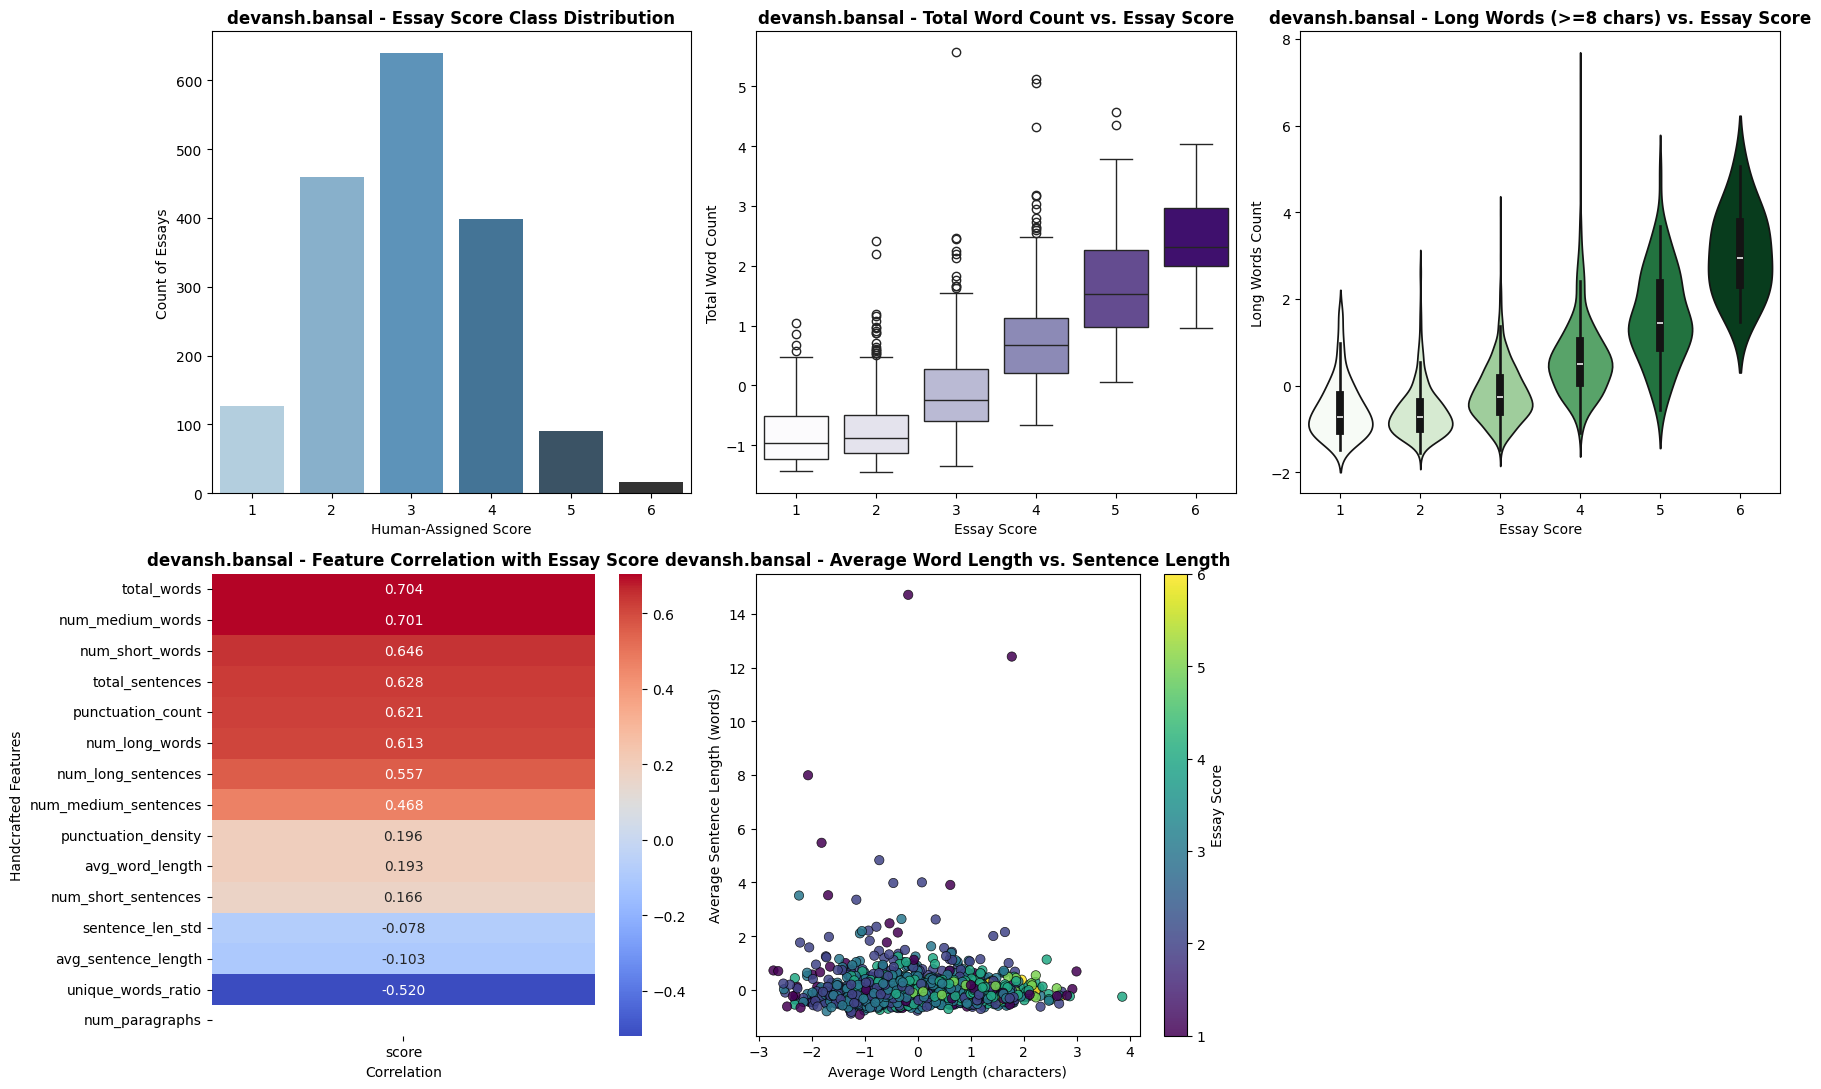

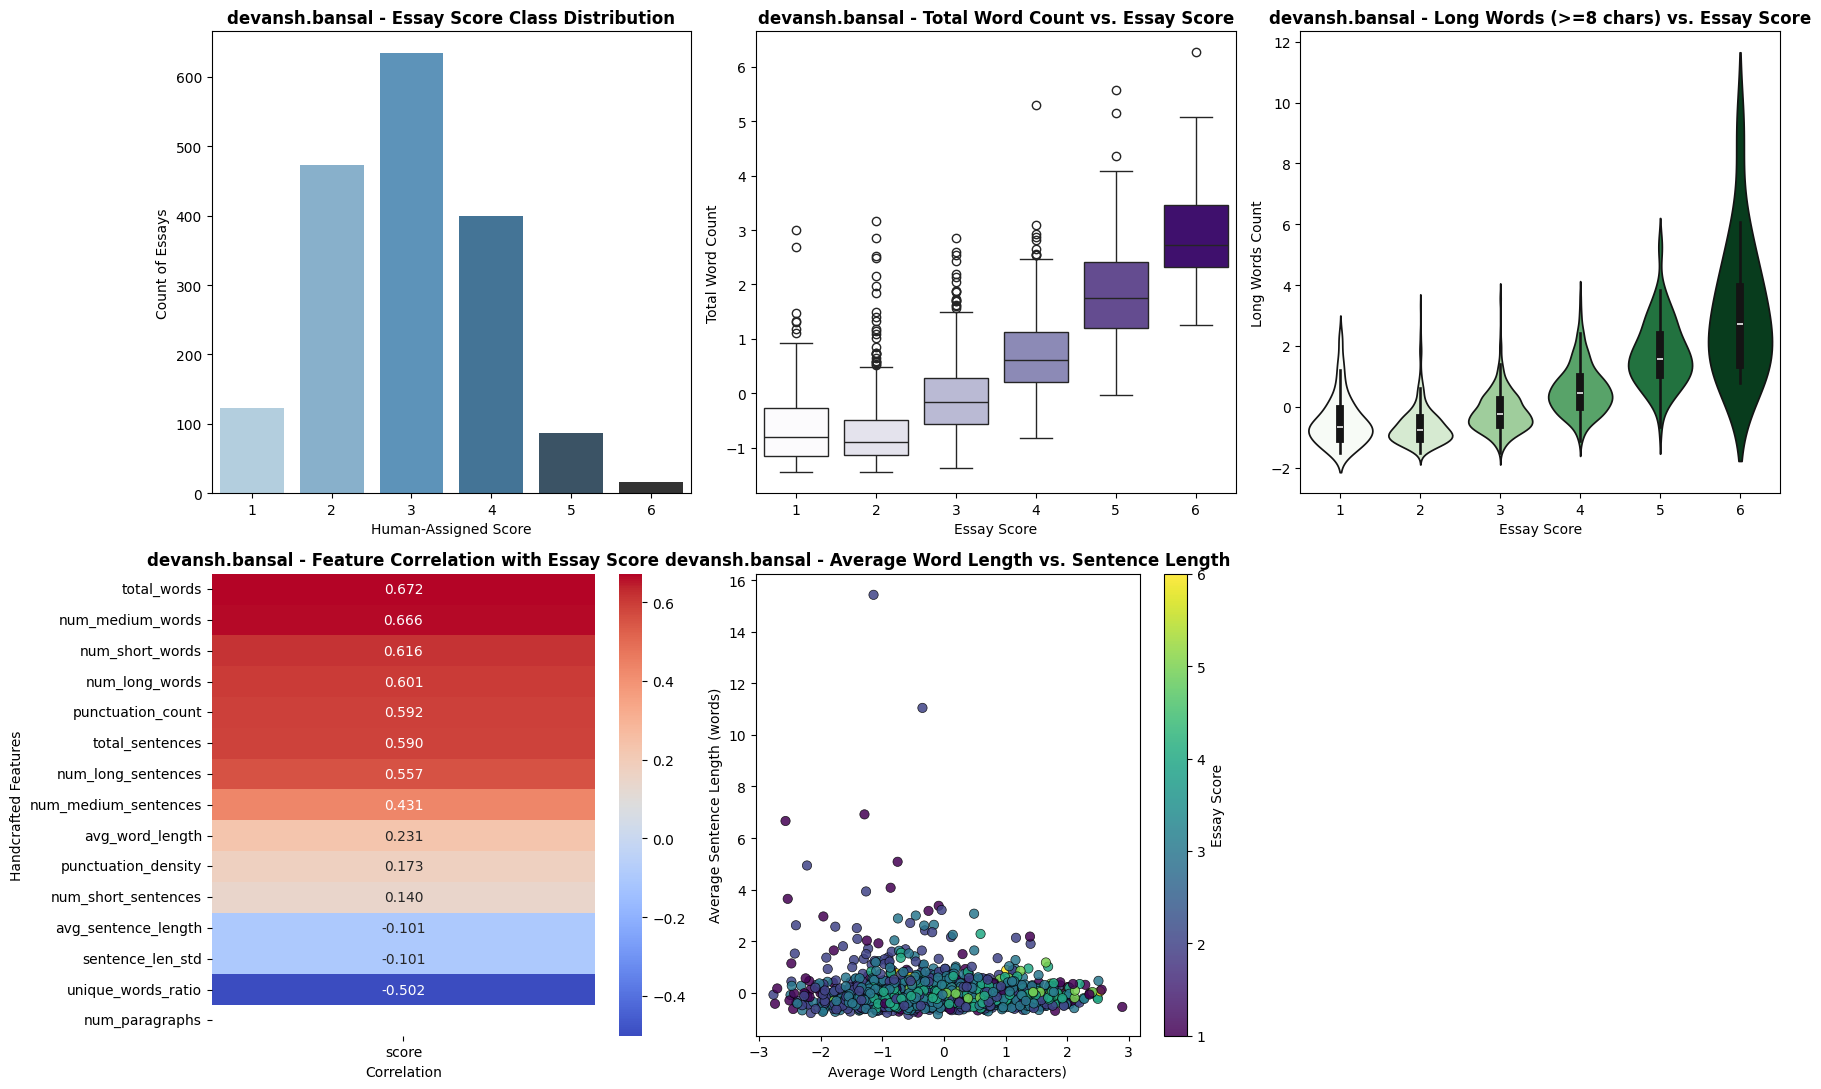

In [112]:

def plotting_function(df, scores):
    """
    Generates five important graphs
    convert numpy array to dataframe for column names
    """
    df_plot = df.copy()
    df_plot['score'] = scores

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))

    # 1. Target Score Distribution
    sns.countplot(
        x='score',
        hue='score',
        data=df_plot,
        ax=axes[0, 0],
        palette='Blues_d',
        legend=False
    )
    axes[0, 0].set_title(
        "devansh.bansal - Essay Score Class Distribution",
        fontweight='bold'
    )
    axes[0, 0].set_xlabel("Human-Assigned Score")
    axes[0, 0].set_ylabel("Count of Essays")

    # 2. Total Word Count vs Score
    sns.boxplot(
        x='score',
        y='total_words',
        hue='score',
        data=df_plot,
        ax=axes[0, 1],
        palette='Purples',
        legend=False
    )
    axes[0, 1].set_title(
        "devansh.bansal - Total Word Count vs. Essay Score",
        fontweight='bold'
    )
    axes[0, 1].set_xlabel("Essay Score")
    axes[0, 1].set_ylabel("Total Word Count")

    # 3. Long Words Count vs Score
    sns.violinplot(
        x='score',
        y='num_long_words',
        hue='score',
        data=df_plot,
        ax=axes[0, 2],
        palette='Greens',
        legend=False
    )
    axes[0, 2].set_title(
        "devansh.bansal - Long Words (>=8 chars) vs. Essay Score",
        fontweight='bold'
    )
    axes[0, 2].set_xlabel("Essay Score")
    axes[0, 2].set_ylabel("Long Words Count")

    # 4. Correlation Heatmap with Target Score
    corr_series = df_plot.corr()['score'].sort_values(ascending=False)
    corr_df = pd.DataFrame(corr_series).drop('score')

    sns.heatmap(
        corr_df,
        annot=True,
        cmap='coolwarm',
        fmt='.3f',
        cbar=True,
        ax=axes[1, 0]
    )
    axes[1, 0].set_title(
        "devansh.bansal - Feature Correlation with Essay Score",
        fontweight='bold'
    )
    axes[1, 0].set_xlabel("Correlation")
    axes[1, 0].set_ylabel("Handcrafted Features")

    # 5. 2D Feature Scatter
    scatter = axes[1, 1].scatter(
        df_plot['avg_word_length'],
        df_plot['avg_sentence_length'],
        c=df_plot['score'],
        cmap='viridis',
        s=45,
        alpha=0.85,
        edgecolors='k',
        linewidth=0.5
    )

    cbar = fig.colorbar(scatter, ax=axes[1, 1])
    cbar.set_label("Essay Score")

    axes[1, 1].set_title(
        "devansh.bansal - Average Word Length vs. Sentence Length",
        fontweight='bold'
    )
    axes[1, 1].set_xlabel("Average Word Length (characters)")
    axes[1, 1].set_ylabel("Average Sentence Length (words)")

    # Hide the unused 6th subplot 
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()


plotting_function(x_train, y_train)
plotting_function(x_val, y_val)
plotting_function(x_test, y_test)


## 1.3 K-Nearest Neighbors Implementation & Hyperparameter Tuning [20 marks]

### 1.3.1 (a) KNN Regression Implementation from Scratch [15 marks]
We construct a modular, object-oriented `KNN` class from scratch supporting three distance metrics:
1. **Euclidean Distance ($L_2$)**:
   $$d_{\text{Euclidean}}(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_{i=1}^d (u_i - v_i)^2}$$
2. **Manhattan Distance ($L_1$)**:
   $$d_{\text{Manhattan}}(\mathbf{u}, \mathbf{v}) = \sum_{i=1}^d |u_i - v_i|$$
3. **Cosine Distance**:
   $$d_{\text{Cosine}}(\mathbf{u}, \mathbf{v}) = 1 - \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$$

For a query point $\mathbf{x}$, the predicted continuous score is computed as the uniform average of the $K$ nearest training labels:
$$\hat{y}(\mathbf{x}) = \frac{1}{K} \sum_{j \in \mathcal{N}_K(\mathbf{x})} y_j$$

In [113]:
class Distance:

    def compute_euclidean(a, b):
        """Euclidean (L2) distance between vectors a and b."""
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)
        return float(np.linalg.norm(a - b))

    def compute_manhattan(a, b):
        """Manhattan (L1) distance between vectors a and b."""
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)
        return float(np.sum(np.abs(a - b)))

    def compute_cosine(a, b):
        """Cosine distance defined as 1 - cosine_similarity(a, b)."""
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)
        norm_a = np.linalg.norm(a)
        norm_b = np.linalg.norm(b)
        if norm_a == 0 or norm_b == 0:
            # If either vector is zero, define distance as 1.0 unless both are zero (then 0.0).
            if norm_a == 0 and norm_b == 0:
                return 0.0
            return 1.0
        cos_sim = float(np.dot(a, b) / (norm_a * norm_b))
        # numerical safety: clip to [-1, 1]
        cos_sim = max(min(cos_sim, 1.0), -1.0)
        return float(1.0 - cos_sim)

In [114]:
class knn:

    def distance (self, x_train,y_train, x_test, distance_metric):
        '''knn store distance data for a given distance metric'''
        if distance_metric == "euclidean":
            distance_function = Distance.compute_euclidean
        elif distance_metric == "manhattan":
            distance_function = Distance.compute_manhattan
        elif distance_metric == "cosine":
            distance_function = Distance.compute_cosine
        else:
            raise ValueError("Unknown distance metric")


        x_test_np = x_test.to_numpy()
        x_train_np = x_train.to_numpy()
        y_train_np = np.asarray(y_train, dtype=float)
        distances = []

        for i in range(len(x_test_np)):
            test_point = x_test_np[i]

            for j in range(len(x_train_np)):
                train_point = x_train_np[j]
                dist = distance_function(test_point, train_point)
                distances.append((dist, y_train_np[j]))
        distances = sorted(distances, key=lambda x: x[0]) 
        return distances

    def knn_prediction(self,distances, k):
        '''knn predict avg of k closest'''
        predictions = []

        for i in range(len(x_test)):
            nearest = distances[:k]
            scores = [x[1] for x in nearest]
            score_pred = np.mean(scores)
            predictions.append(score_pred)
            
        return np.array(predictions)


### 1.3.2 (b) Hyperparameter Tuning [5 marks]

We evaluate all combinations of distance metrics (Euclidean, Manhattan, Cosine) and values of $K \in \{1, 3, 5, 7, 9, 11, 15, 21\}$ on the validation set.

In [115]:
def mean_sqare_error(true,prediction):
    mse = np.mean((true - prediction) ** 2)
    return mse

def root_mean_sqare_error(true,prediction):
    rmse = np.sqrt(mean_sqare_error(true, prediction))
    return rmse

def r2_score(true, prediction):
    ss_res = np.sum((true - prediction) ** 2)
    ss_tot = np.sum((true - np.mean(true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return r2

def pearson_correlation(true, prediction):
    true_mean = np.mean(true)
    pred_mean = np.mean(prediction)
    numerator = np.sum((true - true_mean) * (prediction - pred_mean))
    denominator = np.sqrt(np.sum((true - true_mean) ** 2) * np.sum((prediction - pred_mean) ** 2))
    if denominator == 0:
        return 0.0
    return numerator / denominator

In [116]:
# hyperparameter tuner bruteforce mainly

k = [1,3,5,7,9,11,15,21]
distance_metrics = ["euclidean", "manhattan", "cosine"]

val_results = []
win_rmse = float('inf')
win_config = None
win_k = None

model = knn()

for dist in distance_metrics:
    metric_distances = model.distance(x_train, y_train, x_val, dist)
    for k_val in k:
        y_pred = model.knn_prediction(metric_distances, k_val)

        mse = mean_sqare_error(y_val, y_pred)
        rmse = root_mean_sqare_error(y_val, y_pred)
        r2 = r2_score(y_val, y_pred)
        pearson = pearson_correlation(y_val, y_pred)

        val_results.append({"Distance Metric": dist, "k": k_val, "MSE": mse, "RMSE": rmse, "R2 Score": r2, "Pearson Correlation": pearson})

        if rmse < win_rmse:
            win_rmse = rmse
            win_config = dist
            win_k = k_val

validation_result  = pd.DataFrame(val_results)
print("Validation Results:")
display(validation_result)

print (f"Best Configuration: Distance Metric = {win_config}, k = {win_k}, RMSE = {win_rmse}")
        

ValueError: operands could not be broadcast together with shapes (1730,) (1732,) 